# SVM on baseline.csv (Predict DX at M06)

In [ ]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
import matplotlib.pyplot as plt

# Load the data
data = pd.read_csv('C:/Users/student/bl(lessexc).csv')

# Create the training and testing feature and label sets
x = data.iloc[:, 1:-1]  # Independent features
y = data.iloc[:, -1]  # Dependent features

# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=42)

# Perform feature scaling
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Define the hyperparameter grid
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.1, 1, 'scale'],
    'kernel': ['linear', 'rbf', 'poly']
}

# Create an SVM classifier
svm = SVC(random_state=1, probability=True)

# Create a grid search object
grid_search = GridSearchCV(svm, param_grid=param_grid, cv=5, n_jobs=-1)

In [60]:
# Fit the grid search object to the training data
grid_search.fit(x_train_scaled, y_train)

GridSearchCV(cv=5, estimator=SVC(probability=True, random_state=1), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10], 'gamma': [0.1, 1, 'scale'],
                         'kernel': ['linear', 'rbf', 'poly']})

In [61]:
# Print the best parameters and the corresponding mean cross-validated score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Get the best hyperparameters
best_params = grid_search.best_params_

Best parameters: {'C': 0.1, 'gamma': 0.1, 'kernel': 'linear'}
Best score: 0.960767113863089


In [ ]:
### Model Training AND Testing

In [62]:
# Train an SVM classifier with the best hyperparameters
svm = SVC(**best_params, probability=True)
svm.fit(x_train_scaled, y_train)

# Make predictions on the training and testing sets
y_train_pred = svm.predict(x_train_scaled)
y_test_pred = svm.predict(x_test_scaled)
y_prob = svm.predict_proba(x_test_scaled)

# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

classification_report = classification_report(y_test, y_test_pred)
print(classification_report)

Training accuracy: 0.9725130890052356
Testing accuracy: 0.9695121951219512
Confusion matrix:
 [[ 49   9   0]
 [  0 163   1]
 [  0   0 106]]
              precision    recall  f1-score   support

           0       1.00      0.84      0.92        58
           1       0.95      0.99      0.97       164
           2       0.99      1.00      1.00       106

    accuracy                           0.97       328
   macro avg       0.98      0.95      0.96       328
weighted avg       0.97      0.97      0.97       328



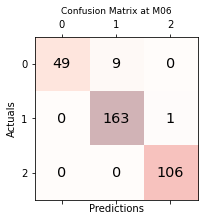

In [18]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Reds, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at M06', fontsize=9)
plt.show()

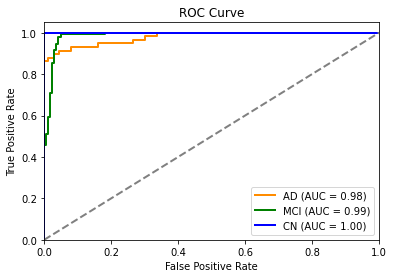

In [19]:

from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

# bl&m06(less).csv (Predict DX at M12)

In [39]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06(lessexc).csv')

# Create the training and testing feature and label sets
x = data.iloc[:, 1:-1]  # Independent features
y = data.iloc[:, -1]  # Dependent features

# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=42)

# Perform feature scaling
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Define the hyperparameter grid
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.1, 1, 'scale'],
    'kernel': ['linear', 'rbf', 'poly']
}

# Create an SVM classifier
svm = SVC(random_state=1)

# Create a grid search object
grid_search = GridSearchCV(svm, param_grid=param_grid, cv=5, n_jobs=-1)

In [40]:
x_train

,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,RAVLT_perc_forgetting_bl,...,ST45CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m06,ABETA_UPENNBIOMK9_04_19_17_m06,TAU_UPENNBIOMK9_04_19_17_m06,PTAU_UPENNBIOMK9_04_19_17_m06,DX_m06
351,83.3,14,1,3.5,9.33,15.33,26,32.0,4.0,87.5000,...,3267.0,2493.0,0.533,1638.0,1567.0,2498.0,843.300000,549.200000,54.940000,0
649,68.2,14,1,1.5,9.00,13.00,30,38.0,6.0,36.3636,...,5273.0,3915.0,0.604,2351.0,1308.0,2298.0,695.300000,237.700000,22.110000,1
1038,81.6,16,0,3.0,9.00,18.00,26,29.0,1.0,100.0000,...,4656.0,4035.0,0.623,3258.0,2667.0,2026.0,1459.000000,250.100000,21.350000,0
249,71.6,14,1,7.0,24.00,34.00,20,28.0,1.0,100.0000,...,4282.0,2688.0,0.640,2272.0,2159.0,1434.0,1064.913718,284.614621,27.130365,0
784,59.0,16,0,2.0,13.00,16.00,29,44.0,4.0,27.2727,...,6114.0,2711.0,0.480,2745.0,215.0,1997.0,1535.000000,142.500000,12.620000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,80.3,18,1,0.0,7.67,10.67,28,37.0,7.0,10.0000,...,3798.0,2810.0,0.709,2479.0,585.0,1902.0,1064.913718,284.614621,27.130365,2
466,71.1,13,0,5.0,21.00,34.00,23,20.0,1.0,75.0000,...,3962.0,2303.0,0.566,1357.0,1003.0,2481.0,1064.913718,284.614621,27.130365,0
121,85.5,20,1,6.0,16.67,22.67,26,26.0,5.0,75.0000,...,3248.0,3815.0,0.637,2263.0,3170.0,1671.0,1064.913718,284.614621,27.130365,0
1044,55.9,19,0,2.5,11.00,20.00,30,33.0,7.0,70.0000,...,3261.0,3872.0,0.478,2377.0,1087.0,1702.0,927.500000,106.300000,8.870000,1


In [41]:
# Fit the grid search object to the training data
grid_search.fit(x_train_scaled, y_train)

GridSearchCV(cv=5, estimator=SVC(random_state=1), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10], 'gamma': [0.1, 1, 'scale'],
                         'kernel': ['linear', 'rbf', 'poly']})

In [42]:
# Print the best parameters and the corresponding mean cross-validated score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Get the best hyperparameters
best_params = grid_search.best_params_

# Train an SVM classifier with the best hyperparameters
svm = SVC(**best_params, probability=True)
svm.fit(x_train_scaled, y_train)

# Make predictions on the training and testing sets
y_train_pred = svm.predict(x_train_scaled)
y_test_pred = svm.predict(x_test_scaled)
y_prob = svm.predict_proba(x_test_scaled)

# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

classification_report = classification_report(y_test, y_test_pred)
print(classification_report)

Best parameters: {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Best score: 0.9332559339525284
Training accuracy: 0.9764397905759162
Testing accuracy: 0.9298780487804879
Confusion matrix:
 [[ 54  16   0]
 [  6 146   1]
 [  0   0 105]]
              precision    recall  f1-score   support

           0       0.90      0.77      0.83        70
           1       0.90      0.95      0.93       153
           2       0.99      1.00      1.00       105

    accuracy                           0.93       328
   macro avg       0.93      0.91      0.92       328
weighted avg       0.93      0.93      0.93       328



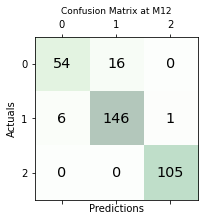

In [43]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Greens, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at M12', fontsize=9)
plt.show()

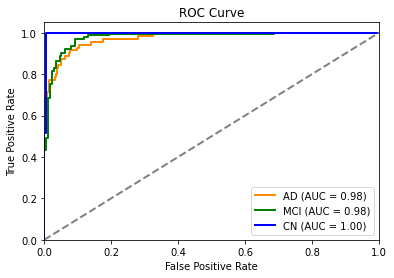

In [44]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

# bl&m06&m12(less).csv (Predict DX at M18)

In [45]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
import matplotlib.pyplot as plt

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06&m12(lessexc).csv')

# Create the training and testing feature and label sets
x = data.iloc[:, 1:-1]  # Independent features
y = data.iloc[:, -1]  # Dependent features

# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=42)

# Perform feature scaling
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Define the hyperparameter grid
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.1, 1, 'scale'],
    'kernel': ['linear', 'rbf', 'poly']
}

# Create an SVM classifier
svm = SVC(random_state=1, probability=True)

# Create a grid search object
grid_search = GridSearchCV(svm, param_grid=param_grid, cv=5, n_jobs=-1)

In [46]:
x_train

,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,RAVLT_perc_forgetting_bl,...,ST45CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16,ABETA_UPENNBIOMK9_04_19_17,TAU_UPENNBIOMK9_04_19_17,PTAU_UPENNBIOMK9_04_19_17,DX
351,83.3,14,1,3.5,9.33,15.33,26,32.0,4.0,87.5000,...,3610.0,2321.0,0.532,1364.0,1527.0,2351.0,843.300000,549.200000,54.940000,0
649,68.2,14,1,1.5,9.00,13.00,30,38.0,6.0,36.3636,...,5409.0,3960.0,0.628,2427.0,1405.0,2340.0,695.300000,237.700000,22.110000,1
1038,81.6,16,0,3.0,9.00,18.00,26,29.0,1.0,100.0000,...,4612.0,4180.0,0.599,3030.0,2633.0,1907.0,1459.000000,250.100000,21.350000,0
249,71.6,14,1,7.0,24.00,34.00,20,28.0,1.0,100.0000,...,4458.0,2948.0,0.553,2513.0,2258.0,1456.0,1064.913718,284.614621,27.130365,0
784,59.0,16,0,2.0,13.00,16.00,29,44.0,4.0,27.2727,...,6176.0,2742.0,0.530,2610.0,256.0,2000.0,1535.000000,142.500000,12.620000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,80.3,18,1,0.0,7.67,10.67,28,37.0,7.0,10.0000,...,3944.0,2673.0,0.755,2384.0,464.0,1992.0,1064.913718,284.614621,27.130365,2
466,71.1,13,0,5.0,21.00,34.00,23,20.0,1.0,75.0000,...,4386.0,2436.0,0.342,1226.0,933.0,2585.0,1064.913718,284.614621,27.130365,0
121,85.5,20,1,6.0,16.67,22.67,26,26.0,5.0,75.0000,...,3396.0,4068.0,0.571,2092.0,3552.0,1577.0,360.600000,118.000000,10.410000,0
1044,55.9,19,0,2.5,11.00,20.00,30,33.0,7.0,70.0000,...,3261.0,3872.0,0.478,2377.0,1087.0,1702.0,927.500000,106.300000,8.870000,1


In [47]:
# Fit the grid search object to the training data
grid_search.fit(x_train_scaled, y_train)

GridSearchCV(cv=5, estimator=SVC(probability=True, random_state=1), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10], 'gamma': [0.1, 1, 'scale'],
                         'kernel': ['linear', 'rbf', 'poly']})

In [48]:
# Print the best parameters and the corresponding mean cross-validated score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Get the best hyperparameters
best_params = grid_search.best_params_

# Train an SVM classifier with the best hyperparameters
svm = SVC(**best_params, probability=True)
svm.fit(x_train_scaled, y_train)

# Make predictions on the training and testing sets
y_train_pred = svm.predict(x_train_scaled)
y_test_pred = svm.predict(x_test_scaled)
y_prob = svm.predict_proba(x_test_scaled)

# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

classification_report = classification_report(y_test, y_test_pred)
print(classification_report)

Best parameters: {'C': 0.1, 'gamma': 0.1, 'kernel': 'linear'}
Best score: 0.9568025455796354
Training accuracy: 0.9947643979057592
Testing accuracy: 0.9542682926829268
Confusion matrix:
 [[ 72  11   0]
 [  3 136   1]
 [  0   0 105]]
              precision    recall  f1-score   support

           0       0.96      0.87      0.91        83
           1       0.93      0.97      0.95       140
           2       0.99      1.00      1.00       105

    accuracy                           0.95       328
   macro avg       0.96      0.95      0.95       328
weighted avg       0.95      0.95      0.95       328



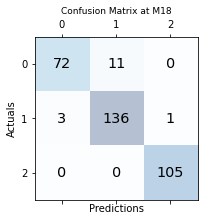

In [49]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Blues, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at M18', fontsize=9)
plt.show()

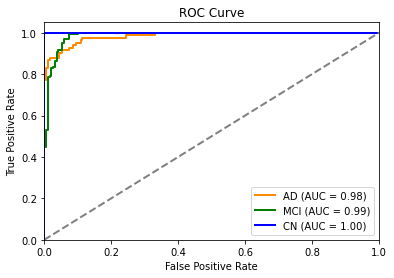

In [32]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()

# bl&m06&m12&m18(less).csv (Predict DX at M24)

In [50]:
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, label_binarize
import matplotlib.pyplot as plt

# Load the data
data = pd.read_csv('C:/Users/student/bl&m06&m12&m18(lessexc).csv')

# Create the training and testing feature and label sets
x = data.iloc[:, 1:-1]  # Independent features
y = data.iloc[:, -1]  # Dependent features

# Split the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.30, random_state=42)

# Perform feature scaling
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

# Define the hyperparameter grid
param_grid = {
    'C': [0.1, 1, 10],
    'gamma': [0.1, 1, 'scale'],
    'kernel': ['linear', 'rbf', 'poly']
}

# Create an SVM classifier
svm = SVC(random_state=1, probability=True)

# Create a grid search object
grid_search = GridSearchCV(svm, param_grid=param_grid, cv=5, n_jobs=-1)

In [51]:
x_train

,AGE_bl,PTEDUCAT_bl,APOE4_bl,CDRSB_bl,ADAS11_bl,ADAS13_bl,MMSE_bl,RAVLT_immediate_bl,RAVLT_learning_bl,RAVLT_perc_forgetting_bl,...,ST45CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST102CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST43TS_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST23CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST30SV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ST73CV_UCSFFSX_11_02_15_UCSFFSX51_08_01_16_m18,ABETA_UPENNBIOMK9_04_19_17_m18,TAU_UPENNBIOMK9_04_19_17_m18,PTAU_UPENNBIOMK9_04_19_17_m18,DX_m18
351,83.3,14,1,3.5,9.33,15.33,26,32.0,4.0,87.5000,...,3610.0,2321.0,0.532,1364.0,1527.0,2351.0,843.300000,549.200000,54.940000,0
649,68.2,14,1,1.5,9.00,13.00,30,38.0,6.0,36.3636,...,5409.0,3960.0,0.628,2427.0,1405.0,2340.0,695.300000,237.700000,22.110000,1
1038,81.6,16,0,3.0,9.00,18.00,26,29.0,1.0,100.0000,...,4612.0,4180.0,0.599,3030.0,2633.0,1907.0,1459.000000,250.100000,21.350000,0
249,71.6,14,1,7.0,24.00,34.00,20,28.0,1.0,100.0000,...,4458.0,2948.0,0.553,2513.0,2258.0,1456.0,1064.913718,284.614621,27.130365,0
784,59.0,16,0,2.0,13.00,16.00,29,44.0,4.0,27.2727,...,6176.0,2742.0,0.530,2610.0,256.0,2000.0,1535.000000,142.500000,12.620000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
330,80.3,18,1,0.0,7.67,10.67,28,37.0,7.0,10.0000,...,3944.0,2673.0,0.755,2384.0,464.0,1992.0,1064.913718,284.614621,27.130365,2
466,71.1,13,0,5.0,21.00,34.00,23,20.0,1.0,75.0000,...,4386.0,2436.0,0.342,1226.0,933.0,2585.0,1064.913718,284.614621,27.130365,0
121,85.5,20,1,6.0,16.67,22.67,26,26.0,5.0,75.0000,...,3396.0,4068.0,0.571,2092.0,3552.0,1577.0,360.600000,118.000000,10.410000,0
1044,55.9,19,0,2.5,11.00,20.00,30,33.0,7.0,70.0000,...,3261.0,3872.0,0.478,2377.0,1087.0,1702.0,927.500000,106.300000,8.870000,1


In [52]:
# Fit the grid search object to the training data
grid_search.fit(x_train_scaled, y_train)

GridSearchCV(cv=5, estimator=SVC(probability=True, random_state=1), n_jobs=-1,
             param_grid={'C': [0.1, 1, 10], 'gamma': [0.1, 1, 'scale'],
                         'kernel': ['linear', 'rbf', 'poly']})

In [53]:
# Print the best parameters and the corresponding mean cross-validated score
print("Best parameters:", grid_search.best_params_)
print("Best score:", grid_search.best_score_)

# Get the best hyperparameters
best_params = grid_search.best_params_

# Train an SVM classifier with the best hyperparameters
svm = SVC(**best_params, probability=True)
svm.fit(x_train_scaled, y_train)

# Make predictions on the training and testing sets
y_train_pred = svm.predict(x_train_scaled)
y_test_pred = svm.predict(x_test_scaled)
y_prob = svm.predict_proba(x_test_scaled)

# Evaluate the performance of the classifier
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Training accuracy:", train_accuracy)
print("Testing accuracy:", test_accuracy)

confusion = confusion_matrix(y_test, y_test_pred)
print("Confusion matrix:\n", confusion)

classification_report = classification_report(y_test, y_test_pred)
print(classification_report)

Best parameters: {'C': 0.1, 'gamma': 0.1, 'kernel': 'linear'}
Best score: 0.9031303749570003
Training accuracy: 0.9777486910994765
Testing accuracy: 0.8932926829268293
Confusion matrix:
 [[ 88  19   0]
 [ 11 105   4]
 [  0   1 100]]
              precision    recall  f1-score   support

           0       0.89      0.82      0.85       107
           1       0.84      0.88      0.86       120
           2       0.96      0.99      0.98       101

    accuracy                           0.89       328
   macro avg       0.90      0.90      0.90       328
weighted avg       0.89      0.89      0.89       328



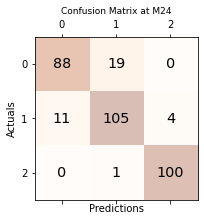

In [54]:
conf_matrix = confusion_matrix(y_true=y_test, y_pred=y_test_pred)
#
# Print the confusion matrix using Matplotlib
#
fig, ax = plt.subplots(figsize=(3, 3))
ax.matshow(conf_matrix, cmap=plt.cm.Oranges, alpha=0.3)
for i in range(conf_matrix.shape[0]):
    for j in range(conf_matrix.shape[1]):
        ax.text(x=j, y=i,s=conf_matrix[i, j], va='center', ha='center', size='x-large')
 
plt.xlabel('Predictions', fontsize=10)
plt.ylabel('Actuals', fontsize=10)
plt.title('Confusion Matrix at M24', fontsize=9)
plt.show()

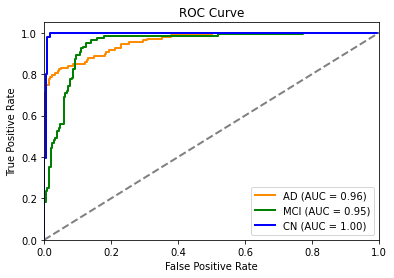

In [38]:
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.preprocessing import label_binarize
from sklearn.metrics import auc

# Binarize the labels
y_binarized = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_binarized.shape[1]

# Compute ROC curve and AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_binarized[:, i], y_prob[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute macro-average ROC curve and AUC
fpr["macro"], tpr["macro"], _ = roc_curve(y_binarized.ravel(), y_prob.ravel())
roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

# Plot ROC curves
plt.figure()
plt.plot(fpr[0], tpr[0], color='darkorange', lw=2,
         label='AD (AUC = %0.2f)' % roc_auc[0])
plt.plot(fpr[1], tpr[1], color='green', lw=2,
         label='MCI (AUC = %0.2f)' % roc_auc[1])
plt.plot(fpr[2], tpr[2], color='blue', lw=2,
         label='CN (AUC = %0.2f)' % roc_auc[2])
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend(loc="lower right")
plt.show()